# 02 — Dados: fontes, procedência, as duas bases, universo, ausência e desfechos

Atualiza `Relatórios do Projeto/02_DADOS.md` (outubro/2026). Pressupõe o notebook 01.

## O que mudou desde o relatório de outubro

| Tema | Relatório 02 (14/10/2026) | Agora | Onde aqui |
|---|---|---|---|
| Base do orientador | "não reproduzível só a partir deste repositório; pedir ao orientador" | entregue, no manifesto (`externo`), **regerada por `src/base_longitudinal.py`** e comparada: 49 colunas idênticas e 8 na tolerância de 1e-9 | §6 |
| `ANO_ALVO` | "sempre `ANO + 1`" | `ANO + 1` **só se a escola existe em *t*+1**; senão vazio. Somado a 2025, que não tem *t*+1, fica vazio em 15,7% das linhas das públicas | §5 |
| Universo | 6.054 linhas, sem dizer o que contém | a união das chaves das 4 planilhas de indicadores; 1.316 linhas não têm valor em nenhuma coluna mantida (escolas só de educação infantil na planilha de ATU; P017) | §4 |
| Série | só 2019–2025 | + base estendida do Gustavo, 2007–2025, com rendimento e 18 itens de infraestrutura; o rendimento comum confere célula por célula (teste 07) | §7 |
| Distribuição do desfecho | médias com escolas privadas incluídas, sem dizer (2022 = "pico") | públicas com taxa na etapa; no AF, 2022 (5,22) é volta ao nível de antes da pandemia, não pico; no EM, 12,05 é o maior desde 2012 | §8 |
| Zeros no alvo | 44% (AF) e 32% (EM), todos os anos juntos | por ano: de 22% a 72% no AF, e o ano de 2020 domina | §8 |
| Missing estrutural | tabela por faixa | medido por coluna nas públicas; ausência nunca vira 0 (regra 5) | §5 |
| Enriquecimento | prioridades da Fase 3 | infraestrutura feita (Gustavo) e testada sem sinal; o resto proposto ou não feito; Fase 3 suspensa | §9 |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
DOCS = OFICIAL / "docs"
REL = GUSTAVO / "saida" / "relatorios"
ENTRADAS = {
    "universo": TABELAS / "universo_por_ano.csv",                 # gerar_tabelas.py
    "rede_loc": TABELAS / "universo_rede_localizacao.csv",        # gerar_tabelas.py
    "colunas_grupo": TABELAS / "colunas_por_grupo.csv",           # gerar_tabelas.py
    "manifesto": TABELAS / "manifesto_por_estagio.csv",           # gerar_tabelas.py
    "papeis": TABELAS / "papeis_variaveis.csv",                   # gerar_tabelas.py
    "problemas": TABELAS / "problemas_por_tipo.csv",              # gerar_tabelas.py
    "comparacao": TABELAS / "comparacao_v1_resumo.csv",           # gerar_tabelas.py
    "ausencia": DOCS / "ausencia_base_longitudinal.csv",          # python -m src.analise_base_longitudinal
    "distribuicao": DOCS / "desfechos_distribuicao.csv",          # idem
    "persistencia": DOCS / "desfechos_persistencia.csv",          # idem
    "cobertura": DOCS / "desfechos_cobertura.csv",                # idem
    "desfecho_ano": REL / "desfecho_por_ano.csv",                 # gustavo/analises/05_descritivo_por_ano.py
    "sobreposicao": REL / "validacao_sobreposicao.txt",           # gustavo/testes/07_validar_sobreposicao.py
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"; os demais pelo script do comentário')
t = {k: pd.read_csv(v) for k, v in ENTRADAS.items() if v.suffix == ".csv"}
universo = t["universo"][t["universo"]["ANO"] != "total"].astype({"ANO": int}).set_index("ANO")

# Parte A — Fontes e procedência

## 1. O que vem do INEP

| Fonte | O que é | Uso no projeto | Arquivos |
|---|---|---|---|
| **Indicadores Educacionais** (2019–2025) | planilhas por indicador e ano, em três níveis (escola, município, Brasil/UF) | **nível escola**: tx_rend (desfecho e rendimento), TDI, ATU, IED; HAD baixado e não usado | 103 zips |
| **Microdados do Censo Escolar** (2019–2025) | uma linha por escola: oferta, infraestrutura, localização diferenciada, matrículas | 18 itens de infraestrutura (via `gustavo/`); candidatos D8; funil Brasil → RR | 7 zips (o de 2025 tem ~537 MB) |
| tx_rend e Censo **2007–2018** | os mesmos, anos anteriores | base estendida do Gustavo | fora desta máquina; só o recorte de RR em `gustavo/cache/` |

A figura abaixo vem do notebook `abandono-escolar/notebooks/01_leitura_e_recorte`. Ela mostra quais
planilhas de indicadores existem em cada ano e quantas linhas de Roraima cada uma tem. "Não identificável"
quer dizer que a planilha não tem coluna de UF com nome técnico: ali a contagem fica vazia, não vira 0
(`DECISOES.md` 2026-11-03).

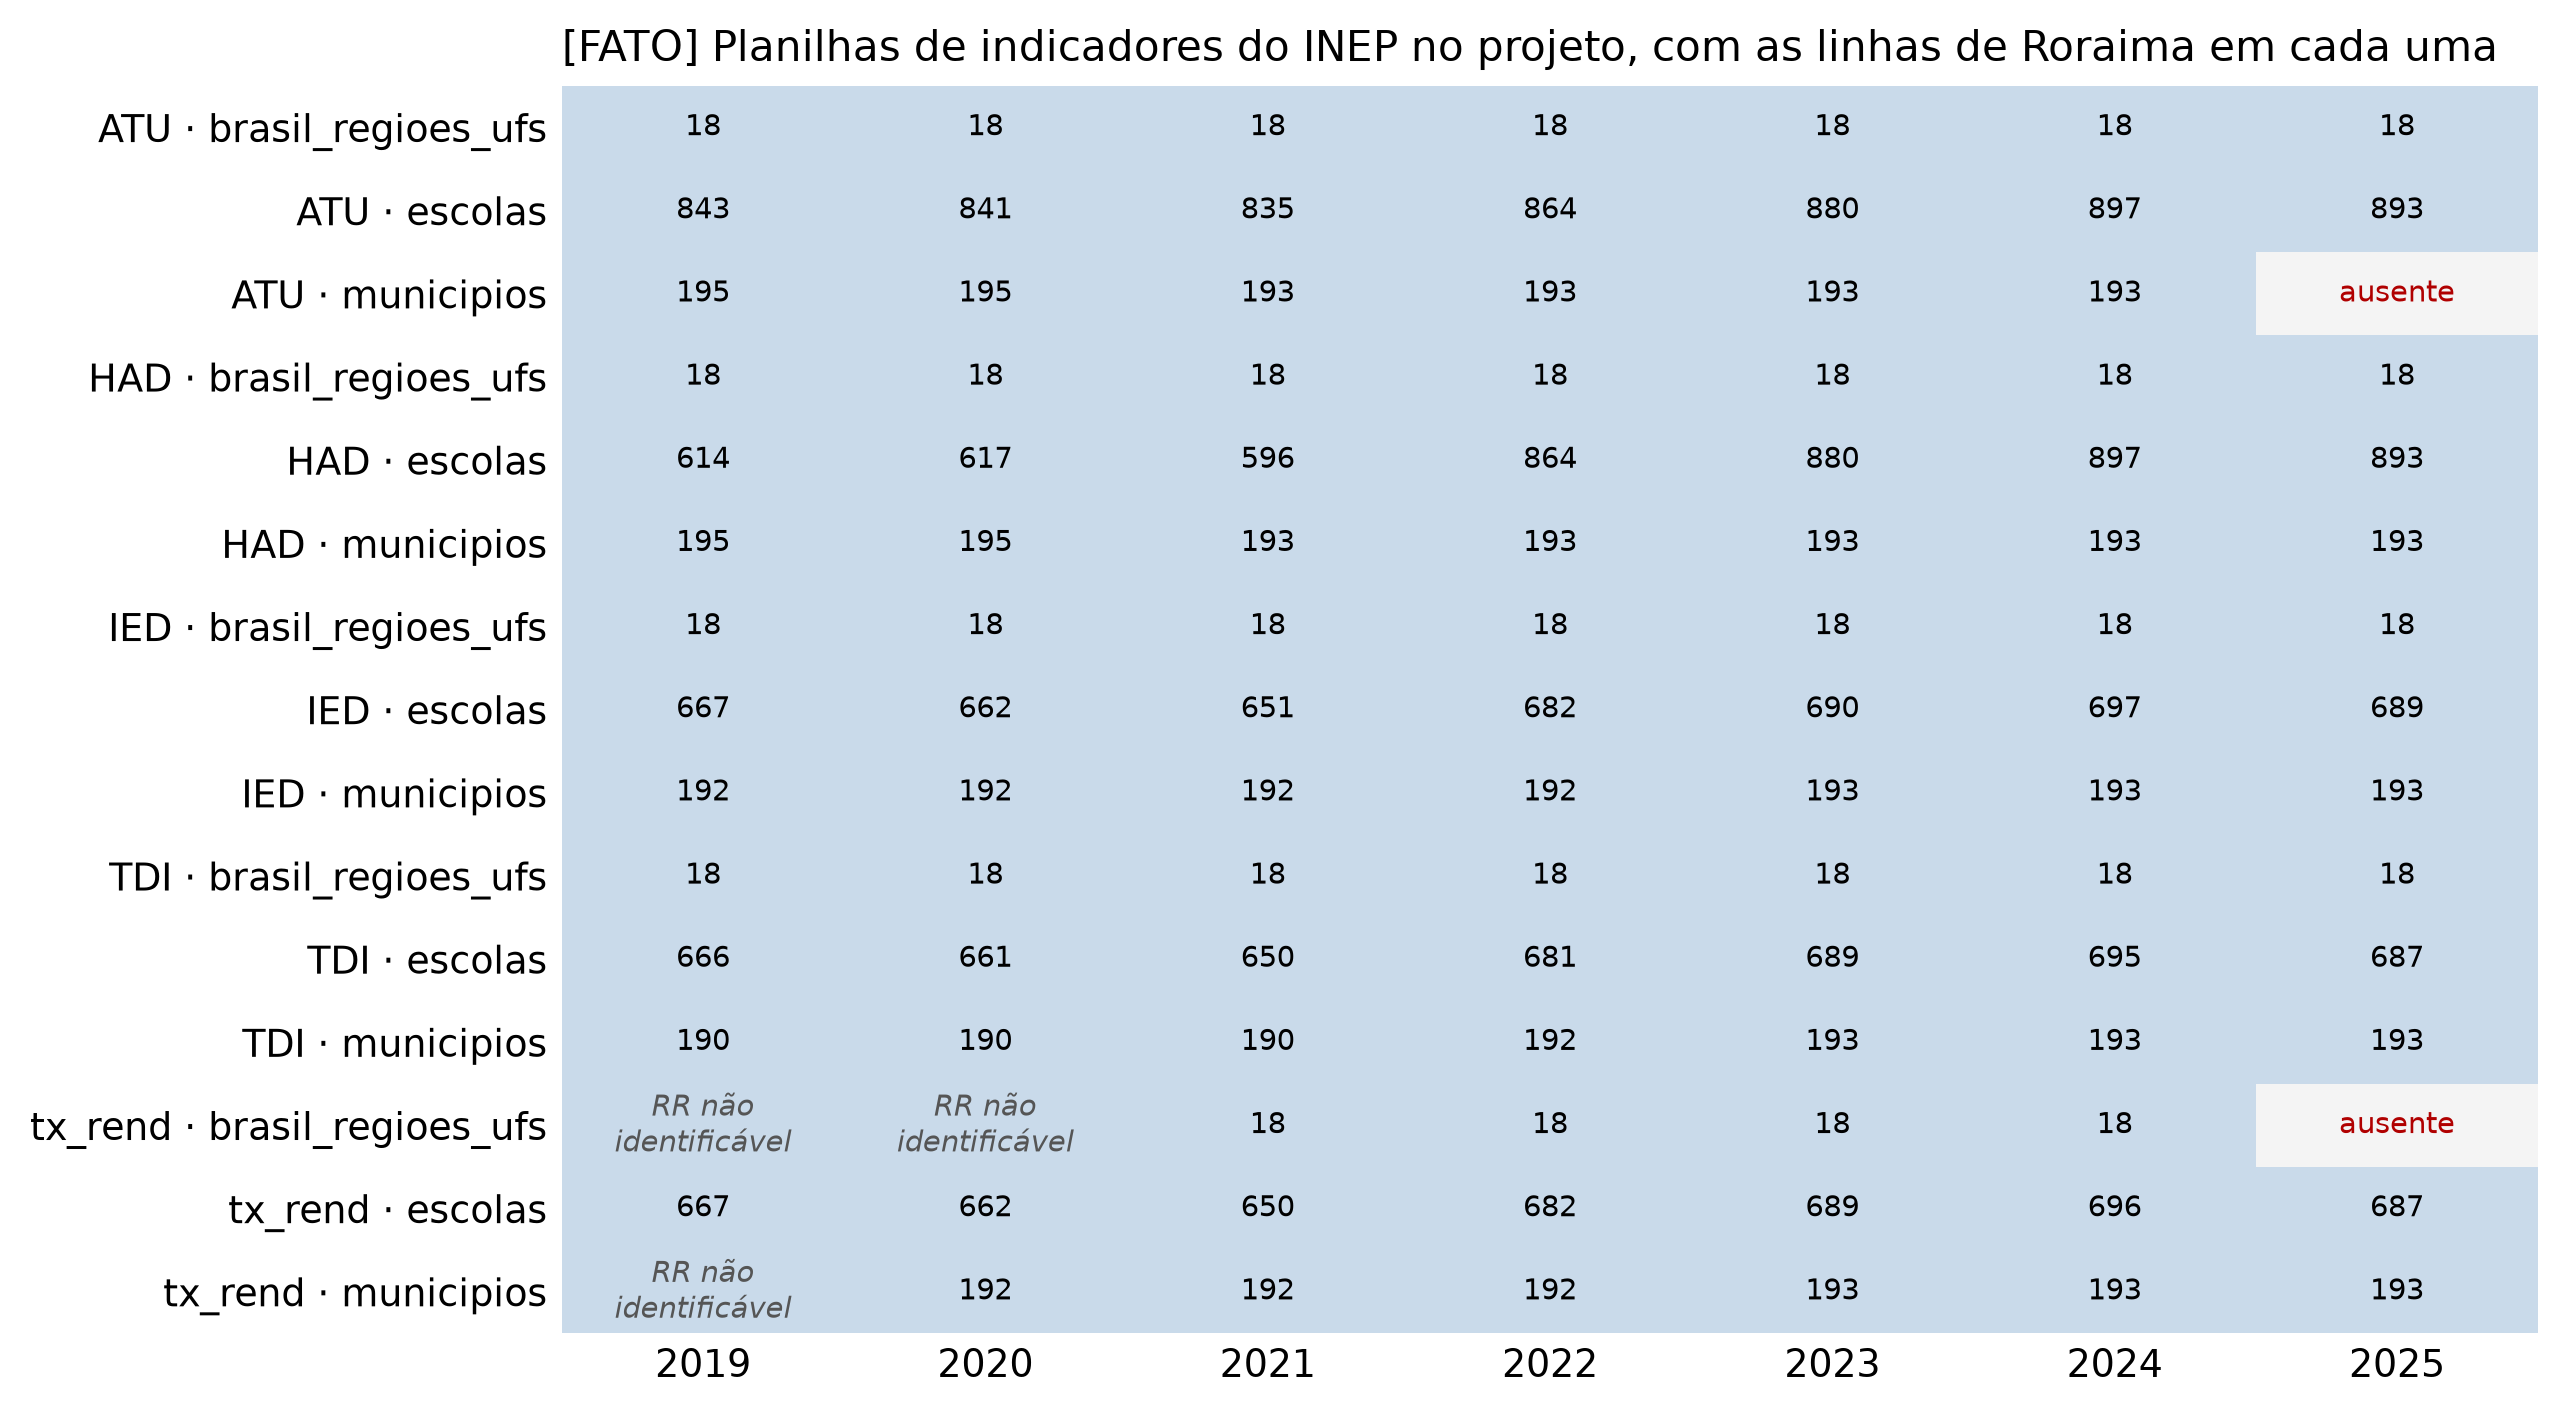

In [3]:
figura_existente(DOCS / "figuras" / "01_indicadores_presentes.png")

## 2. Procedência: o manifesto e o que ele protege

`dados/` é organizada por **estágio do dado** (`DECISOES.md` 2026-09-30):

- `origem/`: os compactados como vieram;
- `bruto/`: extraídos, com o nome original do INEP;
- `interim/`: recorte de RR em Parquet;
- `processado/`: a base final;
- `externo/`: arquivos de terceiros, como a v1.0 do orientador.

O `MANIFEST.csv` guarda o sha256 de cada arquivo. O mesmo hash tem **dois sentidos**:

- em `origem/`, `bruto/` e `externo/`, diz "o arquivo é o mesmo que recebemos"; divergir é **erro**;
- em `processado/`, diz "esta execução deu o mesmo resultado da anterior"; divergir é **aviso** e aparece
  como diff no git.

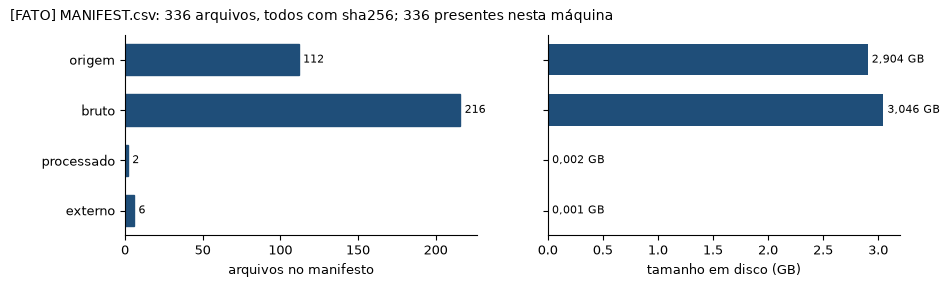

In [4]:
m = t["manifesto"].set_index("estagio").loc[["origem", "bruto", "processado", "externo"]]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
F.barras_contagem(a1, m.index, m["arquivos"], ["funil"] * len(m))
a1.get_legend().remove()
a1.set_xlabel("arquivos no manifesto")
a2.barh(range(len(m))[::-1], m["gb"], color=D.AZUL, height=0.62)
for yi, v in zip(range(len(m))[::-1], m["gb"]):
    a2.annotate(f"{v:.3f} GB".replace(".", ","), (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
a2.set_xlabel("tamanho em disco (GB)")
a2.set_xlim(left=0)
F.titulo_figura(fig, f"MANIFEST.csv: {m['arquivos'].sum()} arquivos, todos com sha256; {m['no_disco'].sum()} presentes nesta máquina", "FATO")
F.salvar(fig, FIGURAS, "02_manifesto")
plt.show()

**Por que tanto cuidado: o INEP muda arquivos sem aviso.** Achados da síntese (§2), todos [FATO]:

| Achado | Tratamento |
|---|---|
| **Revisão silenciosa:** o zip do Censo 2024 é a versão `_defeso` (membros de 08/07/2026) e o de 2025 é `_v2` (31/07/2026), sem nota na página | a versão fica fixada pelo sha256; hash diferente é outra versão e só entra com decisão |
| **md5 publicado não confere** com o `.xlsx` do próprio zip (ATU 2022, TDI 2021, HAD 2020–2021) | a referência é o sha256 do manifesto; o md5 do INEP vira aviso (P007, P020) |
| **Colunas mantidas no layout sem coleta** (valor 0 em todas as escolas do Brasil): água, banheiro e projetor em 2019–2021 | regra de fonte do `gustavo/`: usa a primeira coluna realmente coletada; senão `NaN`, nunca 0 |
| **Identidades contábeis:** aprovação + reprovação + abandono = 100; Σ IED N1..N6 = 100 e ALTO = N4+N5+N6 | nunca as três taxas juntas; IED só N1..N5 (P026) |
| **Layouts do tx_rend mudam:** `.xls` até 2011, cabeçalho em linhas diferentes, `tap_F58` muda de significado entre 2015–17 e 2018–20 | mapear pelo rótulo humano, nunca pelo nome nem pela posição (P009, P014) |
| **Códigos que mudam:** "Particular" × "Privada"; `IN_MED` vira `IN_COMUM_MEDIO_*` em 2025 (162 ou 173 escolas com EM, contra 168 em 2024); `IN_NOTURNO` some | "Particular" unificado; oferta de EM 2025 aguarda decisão (P001, P002) |
| **Certificado TLS:** `download.inep.gov.br` não envia o certificado intermediário | intermediário versionado e conferido por fingerprint (P022) |

**Citação:**

> BRASIL. Instituto Nacional de Estudos e Pesquisas Educacionais Anísio Teixeira (Inep). **Microdados do Censo
> Escolar da Educação Básica 2019–2025.** Brasília: Inep. Acesso em 2 a 15 set. 2026.
>
> BRASIL. Inep. **Indicadores Educacionais: Taxas de Rendimento, Distorção Idade-série, Alunos por Turma,
> Esforço Docente e Horas-aula diária, 2019–2025.** Brasília: Inep. Acesso em 9 a 17 set. 2026.

A Base dos Dados (basedosdados.org) foi descartada para o desfecho, porque não tem a taxa de rendimento por
escola.

## 3. Os repositórios e o bootstrap

```text
Dados-do-Projeto/                       (repositório do Gustavo + trabalho da pesquisadora)
├── abandono-escolar/  → junction para Pmonkey/abandono-escolar (repositório oficial)
│   ├── dados/{origem,bruto,interim,processado,externo}/ + MANIFEST.csv   (dados fora do git; hashes dentro)
│   ├── src/        aquisicao, integridade, manifesto, extrair_brutos_inep, indicadores_inep,
│   │               indicadores_rr, base_longitudinal, filtros, figuras, bootstrap …
│   ├── tests/      70 testes pytest (sem rede, sem ler dados/)
│   ├── docs/       DECISOES.md, SINTESE_DO_PROJETO.md, metodologia_variaveis.md, problemas.csv, CSVs gerados
│   └── notebooks/  01_leitura_e_recorte, 02_descritivo, 03_avaliacao
├── gustavo/
│   ├── programas/  01–05 + 99_pipeline   → saida/base_atual.parquet
│   ├── avaliacao/  painel, baselines, walkforward, bootstrap, metricas + scripts 01–02d
│   ├── analises/   01–05 · testes/ 01–07 · docs/ relatorio_01–06 · cache/ (recorte RR 2007–2025)
├── Relatórios do Projeto/   relatórios 00–07 de outubro (histórico)
└── Contexto do Projeto/     esta pasta
```

O `python -m src.bootstrap` leva um clone limpo ao estado de trabalho. Os passos são: aquisição (baixar
ou `--origem-local`), extração, conferência por sha256, inventários, recorte de RR, base longitudinal,
comparação com a v1.0, catálogo HTML e `git status` limpo no fim.

- Com `--origem-local`, levou **36 min** (30/09/2026), com 26 Parquets idênticos byte a byte.
- O caminho `--baixar` só foi testado contra um servidor falso.
- **Regra 1:** o que existe e confere não é refeito; nada é regravado; arquivo divergente vai para
  `cache_download/divergente/` e o bootstrap para.

# Parte B — A base oficial

## 4. O universo: o que são as 6.054 linhas

A base oficial reproduz a v1.0 do orientador. Uma linha existe se a escola aparece em **pelo menos uma das
quatro planilhas** de indicadores no ano (tx_rend, TDI, ATU ou IED). Não há filtro de rede nem de etapa
na montagem: os recortes são feitos na análise, cada um explícito no código.

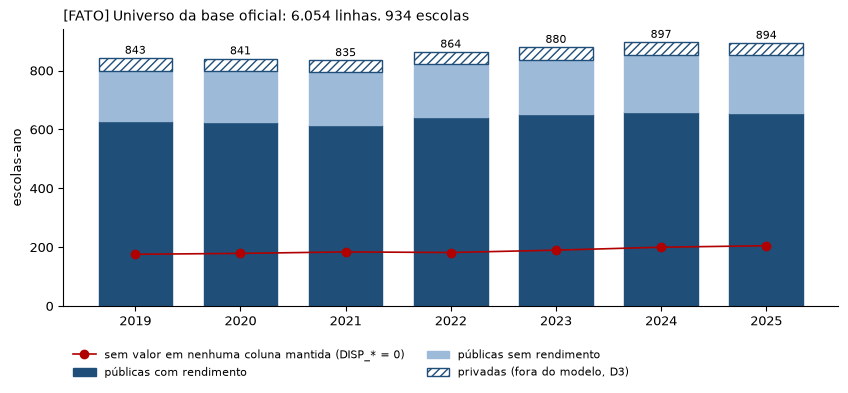

,linhas,publicas,privadas,com_rendimento,publicas_com_rendimento,sem_valor_nas_colunas_mantidas
ANO,,,,,,
2019,843,798,45,666,630,176
2020,841,800,41,660,625,179
2021,835,796,39,650,615,184
2022,864,823,41,679,644,182
2023,880,836,44,689,654,190
2024,897,853,44,695,659,200
2025,894,854,40,687,656,205


In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
anos = universo.index
camadas = [("públicas com rendimento", universo["publicas_com_rendimento"], D.AZUL, None),
           ("públicas sem rendimento", universo["publicas_sem_rendimento"], "#9dbbd9", None),
           ("privadas (fora do modelo, D3)", universo["privadas"], "white", "////")]
base_y = 0
for rotulo, v, cor, hachura in camadas:
    ax.bar(anos, v, bottom=base_y, color=cor, edgecolor=D.AZUL if cor == "white" else cor, hatch=hachura,
           width=0.7, label=rotulo)
    base_y = base_y + v
for a, total in zip(anos, universo["linhas"]):
    ax.annotate(f"{total}", (a, total), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8)
ax.plot(anos, universo["sem_valor_nas_colunas_mantidas"], color=D.VERMELHO, marker="o", linewidth=1.2,
        label="sem valor em nenhuma coluna mantida (DISP_* = 0)")
ax.set_ylabel("escolas-ano")
ax.legend(loc="upper left", fontsize=8, ncol=2, bbox_to_anchor=(0, -0.12))
total = t["universo"].set_index("ANO").loc["total"]
F.titulo(ax, f"Universo da base oficial: {int(total['linhas']):,} linhas, {total['escolas']} escolas".replace(",", "."), "FATO")
F.salvar(fig, FIGURAS, "02_universo_por_ano")
plt.show()
universo[["linhas", "publicas", "privadas", "com_rendimento", "publicas_com_rendimento", "sem_valor_nas_colunas_mantidas"]]

**Como ler:**

- **Privadas** (barra hachurada): ficam na base para descrição e fora do modelo (D3, "regras e público
  distintos").
- **Públicas sem rendimento** (azul claro): não têm desfecho nem preditor de rendimento. Nunca poderiam ser
  avaliadas: são estruturais, não perda de amostra (funil, `DECISOES.md` 2026-11-03).
- **Linha vermelha:** a escola está numa planilha só pelas colunas de educação infantil, que a base não
  mantém. Quase sempre é a de ATU (176 em 2019; P016/P017). Tirá-las do universo é a proposta **P017**,
  ainda sem decisão. Primeiro a base reproduziu a v1.0 e só depois a mudança foi proposta, para não confundir
  bug com decisão.

Rede e localização num ano (contagem gerada por `gerar_tabelas.py`):

In [6]:
rl = t["rede_loc"]
rl[rl["ANO"] == 2024].pivot(index="DEPENDENCIA", columns="LOCALIZACAO", values="linhas").fillna(0).astype(int)

LOCALIZACAO,Rural,Urbana
DEPENDENCIA,,
Estadual,289,80
Federal,2,4
Municipal,295,183
Privada,1,43


Do universo até o painel da avaliação há um funil, com uma figura por etapa. A primeira é da base oficial
(notebook 01 do `abandono-escolar`). A segunda é da base avaliada, a do `gustavo/` (notebook 02), em 2023.

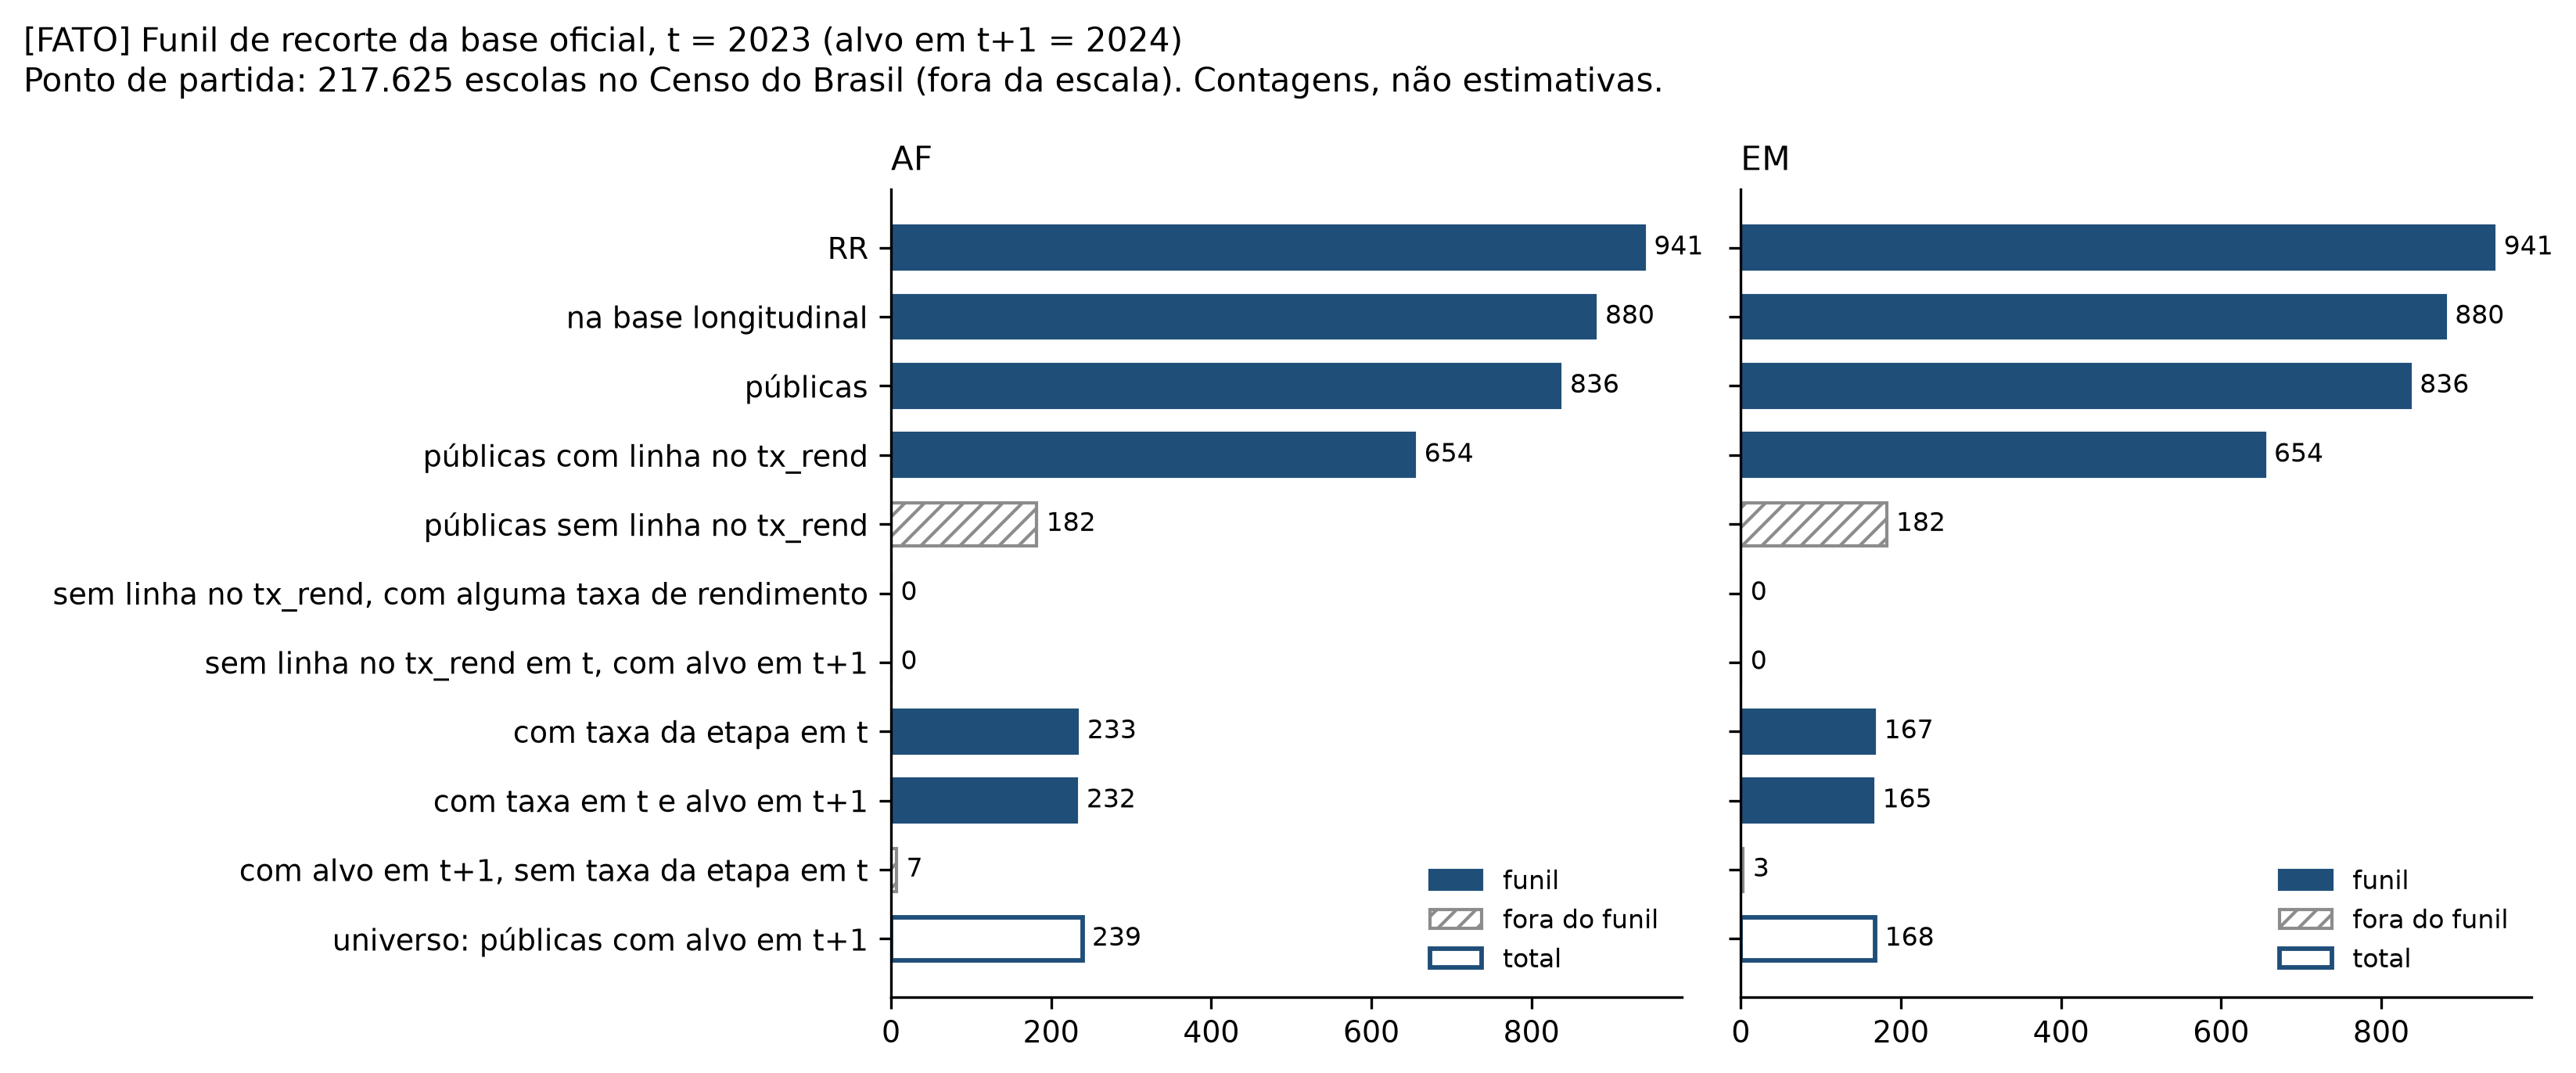

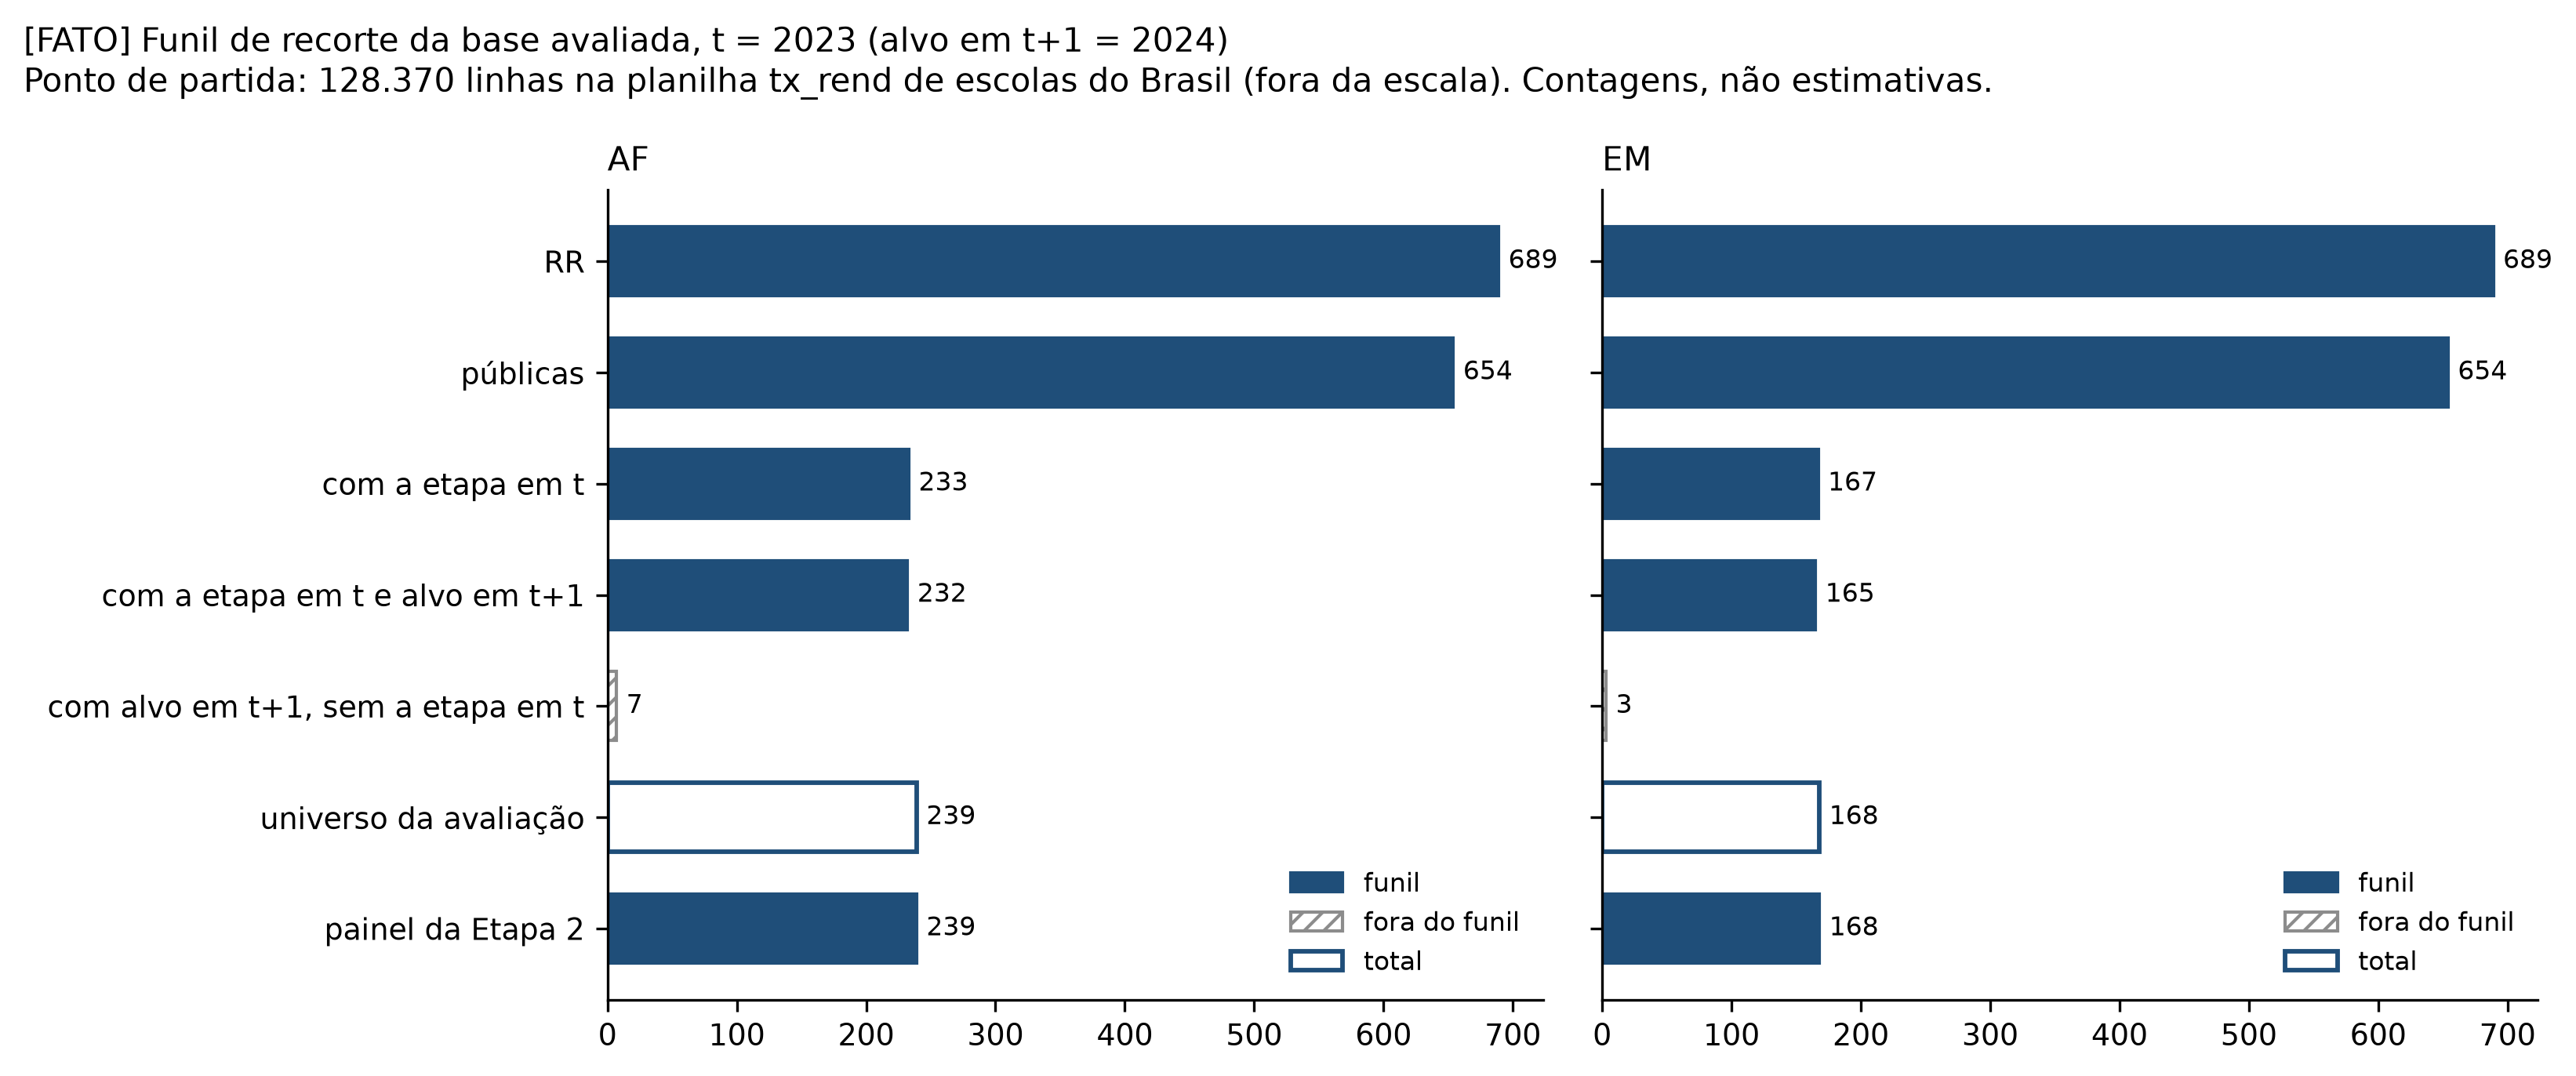

In [7]:
figura_existente(DOCS / "figuras" / "01_funil_base_oficial_2023.png", largura=760)
figura_existente(GUSTAVO / "saida" / "figuras" / "02_funil_base_avaliada_2023.png", largura=760)

## 5. As 59 colunas, os papéis e a ausência

As colunas da base oficial se dividem em 8 de identificação, 5 indicadores de disponibilidade
(`REDE_PUBLICA` e os quatro `DISP_*`), 4 de ATU, 4 de TDI e 14 de IED. Completam o total 12 taxas de
rendimento do ano, 3 `_LAG1`, 6 `_DELTA1` e 3 `_T1` (desfechos).

Desde 30/09/2026 cada variável tem **um único papel** (`docs/dicionario_anotado.csv`; metodologia §4).
Com isso, nenhuma coluna é ao mesmo tempo filtro e preditor, e nenhuma vira preditor por engano.

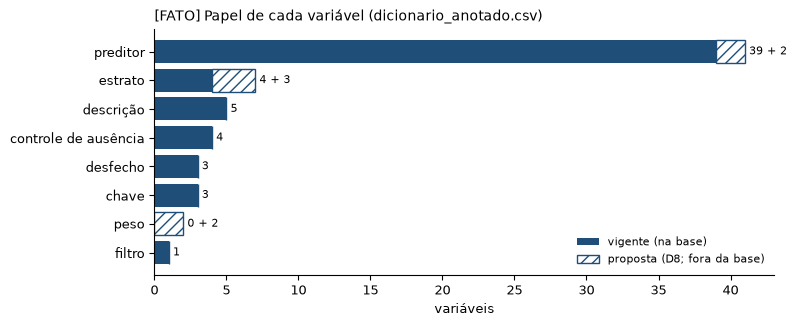

In [8]:
p = t["papeis"].pivot(index="papel", columns="status", values="variaveis").fillna(0).astype(int)
p = p.loc[p.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(p.index, p["vigente"], color=D.AZUL, label="vigente (na base)")
ax.barh(p.index, p.get("proposta", 0), left=p["vigente"], color="white", edgecolor=D.AZUL, hatch="///",
        label="proposta (D8; fora da base)")
for i, (v, pr) in enumerate(zip(p["vigente"], p.get("proposta", 0))):
    ax.annotate(f"{v}" + (f" + {pr}" if pr else ""), (v + pr, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("variáveis")
ax.legend(loc="lower right", fontsize=8)
F.titulo(ax, "Papel de cada variável (dicionario_anotado.csv)", "FATO")
F.salvar(fig, FIGURAS, "02_papeis_variaveis")
plt.show()

| Papel | Exemplos | Regra |
|---|---|---|
| chave | `ANO`, `CO_ENTIDADE`, `ANO_ALVO` | `CO_ENTIDADE` é texto (regra 6); `ANO_ALVO` vazio se a escola não existe em *t*+1 |
| filtro | `REDE_PUBLICA` | define o universo (D3) |
| estrato | `DEPENDENCIA`, `LOCALIZACAO`; propostos: indígena, localização diferenciada | define o B2 e a equidade |
| controle de ausência | `DISP_*` | distingue "a escola não está na planilha" de "está, mas não tem a etapa" |
| preditor | TDI, ATU, IED N1..N5, rendimento defasado | nunca as três taxas de rendimento juntas, nem N6/ALTO com N1..N5 (P026) |
| desfecho | `ABANDONO_FUN_AF_T1`, `ABANDONO_MED_T1` | só desfecho, nunca preditor |
| peso (proposta) | `QT_MAT_FUND_AF`, `QT_MAT_MED` | uma taxa de escola pequena pesa igual à de uma grande (P018) |

**Ausência nas escolas públicas.** A falta é **estrutural**, não aleatória: a escola não tem a etapa, ou a
fonte não existia no ano. Por isso nunca vira 0 (regra 5) e cada painel é montado só com as escolas da sua
etapa (D2).

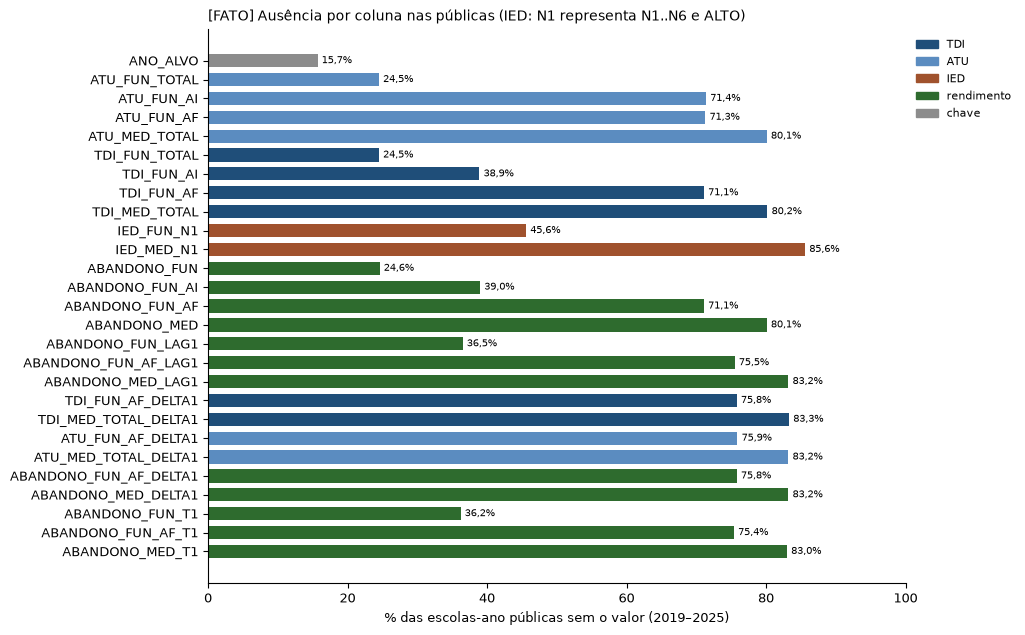

In [9]:
aus = t["ausencia"].copy()
aus = aus[aus["pct_ausente_publicas"] > 0]
grupos = [("TDI_", "TDI"), ("ATU_", "ATU"), ("IED_", "IED"), ("ABANDONO_", "rendimento"),
          ("APROVACAO_", "rendimento"), ("REPROVACAO_", "rendimento"), ("ANO_ALVO", "chave")]
aus["grupo"] = [next((g for pre, g in grupos if v.startswith(pre)), "outro") for v in aus["variavel"]]
aus = aus[~aus["variavel"].str.contains("_N[2-6]$|_ALTO$|APROVACAO_|REPROVACAO_", regex=True)]   # mostra N1 por IED; aprovação/reprovação = abandono
cores = {"TDI": D.AZUL, "ATU": "#5b8cc0", "IED": "#a0522d", "rendimento": "#2e6b2e", "chave": D.CINZA}
aus = aus.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.barh(aus["variavel"], aus["pct_ausente_publicas"], color=[cores[g] for g in aus["grupo"]], height=0.7)
for i, v in enumerate(aus["pct_ausente_publicas"]):
    ax.annotate(f"{v:.1f}%".replace(".", ","), (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=7)
ax.set_xlim(0, 100)
ax.set_xlabel("% das escolas-ano públicas sem o valor (2019–2025)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=g) for g, c in cores.items()], loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)
F.titulo(ax, "Ausência por coluna nas públicas (IED: N1 representa N1..N6 e ALTO)", "FATO")
F.salvar(fig, FIGURAS, "02_ausencia_por_coluna")
plt.show()

**Como ler:**

- `*_MED*` falta em ~80% das públicas e `*_FUN_AF*` em ~71%: só uma parte das escolas tem cada etapa.
- O **`ATU_FUN_AI`** falta muito mais que o `TDI_FUN_AI` (71% contra 39%). A diferença são as turmas
  multisseriadas, comuns no rural e indígena, que o INEP exclui da média por série (P016). A proposta **D9**
  é usar `ATU_FUN_TOTAL` com um indicador de multisseriada.
- O IED falta mais (46% e 86%) porque só existe desde 2021: em 2019–2020 a ausência é "por falta do
  arquivo, não zero" (P019).
- `_LAG1` e `_DELTA1` faltam em 2019, porque a base oficial não tem 2018.

## 6. A âncora: regerar a base do orientador

A v1.0 chegou pronta em 17/09/2026, sem o script que a gerou. O `src/base_longitudinal.py` a regera com
regras explícitas:

- **universo:** a união das chaves;
- **identidade da escola:** o primeiro valor não nulo na ordem tx_rend → TDI → ATU → IED;
- **`ANO_ALVO`:** só se a escola existe em *t*+1;
- **derivadas:** por junção explícita em ANO ± 1, nunca por `shift()`;
- **mapeamento posicional** do tx_rend 2019–2020: conferido contra 63 rótulos humanos.

Depois compara coluna a coluna, **comparando a ausência antes dos valores**: como NaN ≠ NaN, comparar só
os valores faria colunas divergentes parecerem iguais.

In [10]:
display(t["comparacao"])
print("A linha 'idêntica' inclui a chave ANO + CO_ENTIDADE; as 8 'na tolerância' são IED_*_ALTO e os *_DELTA1 (soma e diferença em ponto flutuante).")
resumo = [l.strip() for l in ENTRADAS["sobreposicao"].read_text(encoding="utf-8").splitlines() if l.startswith("RESUMO")]
print("Teste 07 (rendimento 2019–2025, base_atual × base oficial):", *resumo)

,classificacao,colunas,maior_diferenca
0,idêntica,50,0.000000e+00
1,idêntica na tolerância,8,1.421085e-14


A linha 'idêntica' inclui a chave ANO + CO_ENTIDADE; as 8 'na tolerância' são IED_*_ALTO e os *_DELTA1 (soma e diferença em ponto flutuante).
Teste 07 (rendimento 2019–2025, base_atual × base oficial): RESUMO: 25 OK, 0 falhas


O teste 07 fecha a cadeia de confiança: v1.0 ⇄ base oficial ⇄ `base_atual`. O rendimento de 2019–2025 que
a avaliação usa (do `gustavo/`) é o mesmo da base oficial, célula por célula. O teste confere também os
`_LAG1` e `_DELTA1` de 2020 em diante: em 2019 eles dependem de 2018, que só o `gustavo/` tem.

# Parte C — A base estendida (`gustavo/`)

## 7. O que ela acrescenta, e o que lhe falta

Ela tem **mais anos e outra família de variáveis**, e não tem TDI, ATU nem IED (comparação por coluna,
gerada por `gerar_tabelas.py`):

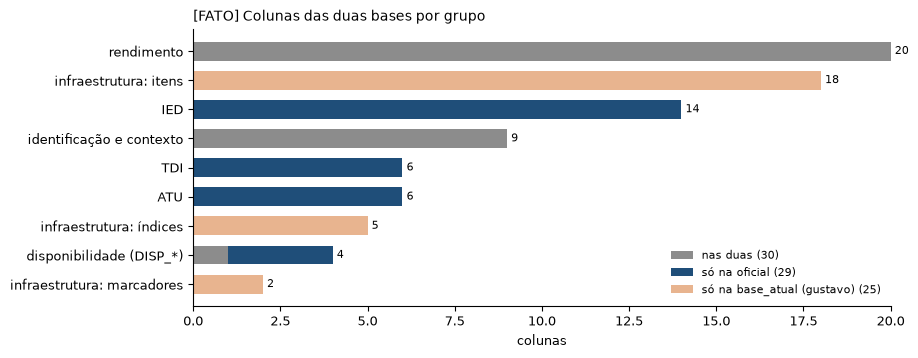

In [11]:
cg = t["colunas_grupo"].pivot(index="grupo", columns="onde", values="colunas").fillna(0).astype(int)
ordem = ["nas duas", "só na oficial", "só na base_atual (gustavo)"]
cg = cg[[c for c in ordem if c in cg.columns]]
cg = cg.loc[cg.sum(axis=1).sort_values().index]
cores = {"nas duas": D.CINZA, "só na oficial": D.AZUL, "só na base_atual (gustavo)": "#e8b48f"}
fig, ax = plt.subplots(figsize=(9, 3.6))
esquerda = pd.Series(0, index=cg.index)
for c in cg.columns:
    ax.barh(cg.index, cg[c], left=esquerda, color=cores[c], label=f"{c} ({cg[c].sum()})", height=0.65)
    esquerda = esquerda + cg[c]
for i, v in enumerate(esquerda):
    ax.annotate(f"{v}", (v, i), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
ax.set_xlabel("colunas")
ax.legend(loc="lower right", fontsize=8)
F.titulo(ax, "Colunas das duas bases por grupo", "FATO")
F.salvar(fig, FIGURAS, "02_colunas_das_bases")
plt.show()

O pipeline do Gustavo (relatórios `gustavo/docs/relatorio_01` a `05`, 07–14/10/2026):

- **Rendimento 2007–2025:** três gerações de layout do INEP, harmonizadas pelo rótulo humano.
- **18 itens de infraestrutura** do Censo (Almeida & Mussato, 2023, Quadro 3), em 4 dimensões:
  - IIB, infraestrutura básica: água, banheiro, lixo, energia;
  - IDA, administrativa: despensa, refeitório, diretoria, sala dos professores, secretaria;
  - IDP, pedagógica: biblioteca, laboratório de informática, pátios, quadra;
  - IEP, equipamentos: computador, impressora, internet, projetor.
- **Regra de fonte:** usa a primeira coluna realmente coletada no Brasil; senão `NaN`, nunca 0.
- **Índices `zano`:** soma dos itens, z-score dentro do ano, e IIE = 1ª componente principal das quatro
  dimensões, com pesos calculados no próprio ano. Não usa dado futuro: o teste 02 prova isso perturbando os
  dados. As normalizações `zref19` e `prop` foram descartadas.
- **2007–2011:** IDA usa 2 itens e IDP 3 (o Censo não perguntava os outros). A concordância com a versão
  completa é de 0,89–0,93 (Spearman) nas dimensões e 0,99 no IIE. `INFRA_ITENS_COMPLETOS` e
  `INFRA_FONTE_ARTIGO` são marcadores para filtrar e auditar, **não features**.

**Limite principal:** os zips de 2007–2018 estavam na máquina do Gustavo. Foram conferidos uma vez, 19 de 19
anos, em 14/10/2026, mas não são reverificáveis aqui e não estão no manifesto (síntese §5.2). Estender a
série oficial (D11) continua sem decisão.

# Parte D — O desfecho

## 8. Abandono por ano, zeros e persistência

Escolas públicas com taxa na etapa, 2007–2025 (`gustavo/analises/05_descritivo_por_ano.py`). De 2019 em
diante, a série confere com `docs/desfechos_distribuicao.csv`, que vem de código independente (teste 06).

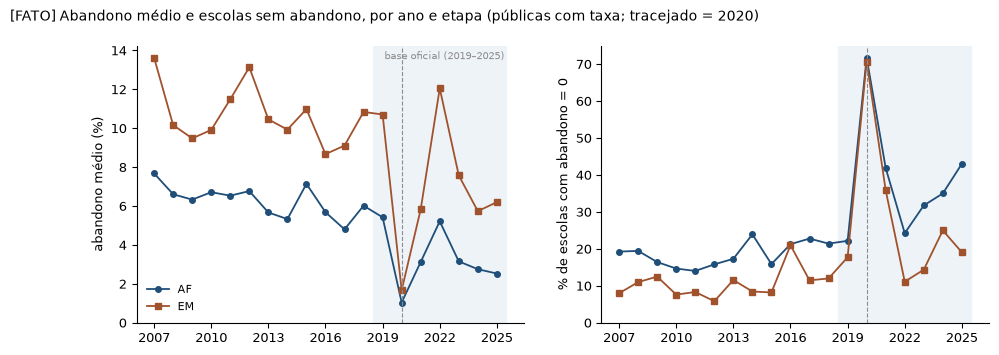

n        media        pct_zero       
etapa     AF     EM    AF     EM       AF     EM
ano                                             
2019   239.0  158.0  5.42  10.71    22.18  17.72
2020   237.0  157.0  1.04   1.67    71.73  70.70
2021   234.0  159.0  3.13   5.83    41.88  35.85
2022   235.0  162.0  5.22  12.05    24.26  11.11
2023   233.0  167.0  3.16   7.58    31.76  14.37
2024   240.0  168.0  2.76   5.74    35.00  25.00
2025   244.0  173.0  2.53   6.20    43.03  19.08

In [12]:
da = t["desfecho_ano"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
for etapa, cor, marcador in [("AF", D.AZUL, "o"), ("EM", "#a0522d", "s")]:
    s = da[da["etapa"] == etapa]
    a1.plot(s["ano"], s["media"], color=cor, marker=marcador, markersize=4, linewidth=1.3, label=etapa)
    a2.plot(s["ano"], s["pct_zero"], color=cor, marker=marcador, markersize=4, linewidth=1.3, label=etapa)
a1.set_ylabel("abandono médio (%)")
a2.set_ylabel("% de escolas com abandono = 0")
for ax in (a1, a2):
    ax.axvspan(2018.5, 2025.5, color="#eef3f8", zorder=0)
    ax.axvline(2020, color=D.CINZA, linestyle="--", linewidth=0.8)
    ax.set_xticks(range(2007, 2026, 3))
    ax.set_ylim(bottom=0)
a1.legend(fontsize=8)
a1.text(2025.4, a1.get_ylim()[1] * 0.98, "base oficial (2019–2025)", fontsize=7, color=D.CINZA, va="top", ha="right")
F.titulo_figura(fig, "Abandono médio e escolas sem abandono, por ano e etapa (públicas com taxa; tracejado = 2020)", "FATO")
F.salvar(fig, FIGURAS, "02_desfecho_por_ano")
plt.show()
da[da["ano"] >= 2019].pivot(index="ano", columns="etapa", values=["n", "media", "pct_zero"]).round(2)

**O que a figura mostra:**

- **2020 é uma ruptura:** o abandono quase zera (AF 1,04%; EM 1,67%) e 71,7% das escolas do AF ficam com 0.
  Por isso o ano fica na base com sensibilidade S1–S4 (D6), e por isso a primeira dobra do walk-forward
  treina com um alvo quase todo zero.
- **2022 não é pico no AF:** 5,22% fica dentro da faixa de 2007–2019 (4,80 a 7,68) e abaixo de 2019 (5,42).
  É volta ao nível de antes da pandemia. A hipótese que se apoiava em 2022 como pico foi refutada
  (síntese §4 #2). No EM, 12,05% é o maior desde 2012.
- **O EM abandona cerca do dobro do AF** em quase todos os anos. Isso justifica os dois painéis (D2), junto
  com as redes (EM só estadual e federal) e os tamanhos (~235 escolas no AF, ~165 no EM por ano).
- **Massa em zero e cauda longa:** a média engana. O Recall@K, que só depende da ordem das escolas, é a
  métrica que decide (notebook 03).

**Persistência.** O abandono de uma escola num ano diz pouco sobre o do ano seguinte. A tabela usa os pares
de todas as transições, inclusive 2024→2025: é [EXPLORATÓRIO], porque olha o desfecho do teste bloqueado
(um dos 5 usos registrados).

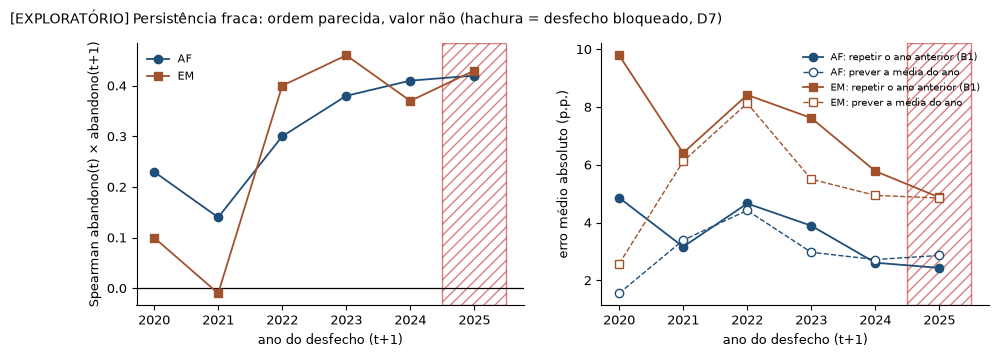

In [13]:
ps = t["persistencia"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
for etapa, cor, marcador in [("AF", D.AZUL, "o"), ("EM", "#a0522d", "s")]:
    s = ps[ps["etapa"] == etapa]
    x = s["transicao"].str.slice(6, 10).astype(int)
    a1.plot(x, s["spearman_t_t1"], color=cor, marker=marcador, linewidth=1.3, label=etapa)
    a2.plot(x, s["mae_b1_persistencia"], color=cor, marker=marcador, linewidth=1.3, label=f"{etapa}: repetir o ano anterior (B1)")
    a2.plot(x, s["mae_b0_media"], color=cor, marker=marcador, linewidth=1.0, linestyle="--", markerfacecolor="white",
            label=f"{etapa}: prever a média do ano")
F.linha_zero(a1, "v")
a1.set_ylabel("Spearman abandono(t) × abandono(t+1)")
a2.set_ylabel("erro médio absoluto (p.p.)")
for ax in (a1, a2):
    ax.set_xlabel("ano do desfecho (t+1)")
    ax.axvspan(2024.5, 2025.5, facecolor="white", edgecolor=D.VERMELHO, hatch="///", alpha=0.5, zorder=0)
a1.legend(fontsize=8)
a2.legend(fontsize=7, loc="upper right")
F.titulo_figura(fig, "Persistência fraca: ordem parecida, valor não (hachura = desfecho bloqueado, D7)", "EXPLORATÓRIO")
F.salvar(fig, FIGURAS, "02_persistencia")
plt.show()

**Leitura:**

- A correlação de ordem fica entre −0,01 e 0,46. Em **9 das 12 transições**, prever a média erra menos do que
  repetir o ano anterior (3 de 6 no AF, 6 de 6 no EM). A média aqui é a do próprio ano, um oráculo; na
  Etapa 1, o B0 usa só anos anteriores.
- Por isso todo modelo é comparado com os dois baselines, e a métrica que decide é de **ordem** (Recall@K),
  não de valor. A persistência ordena melhor que o acaso, mesmo quando erra no valor.
- A cobertura de cada indicador no painel da avaliação, por ano e etapa, está na figura do notebook 02 do
  `abandono-escolar`:

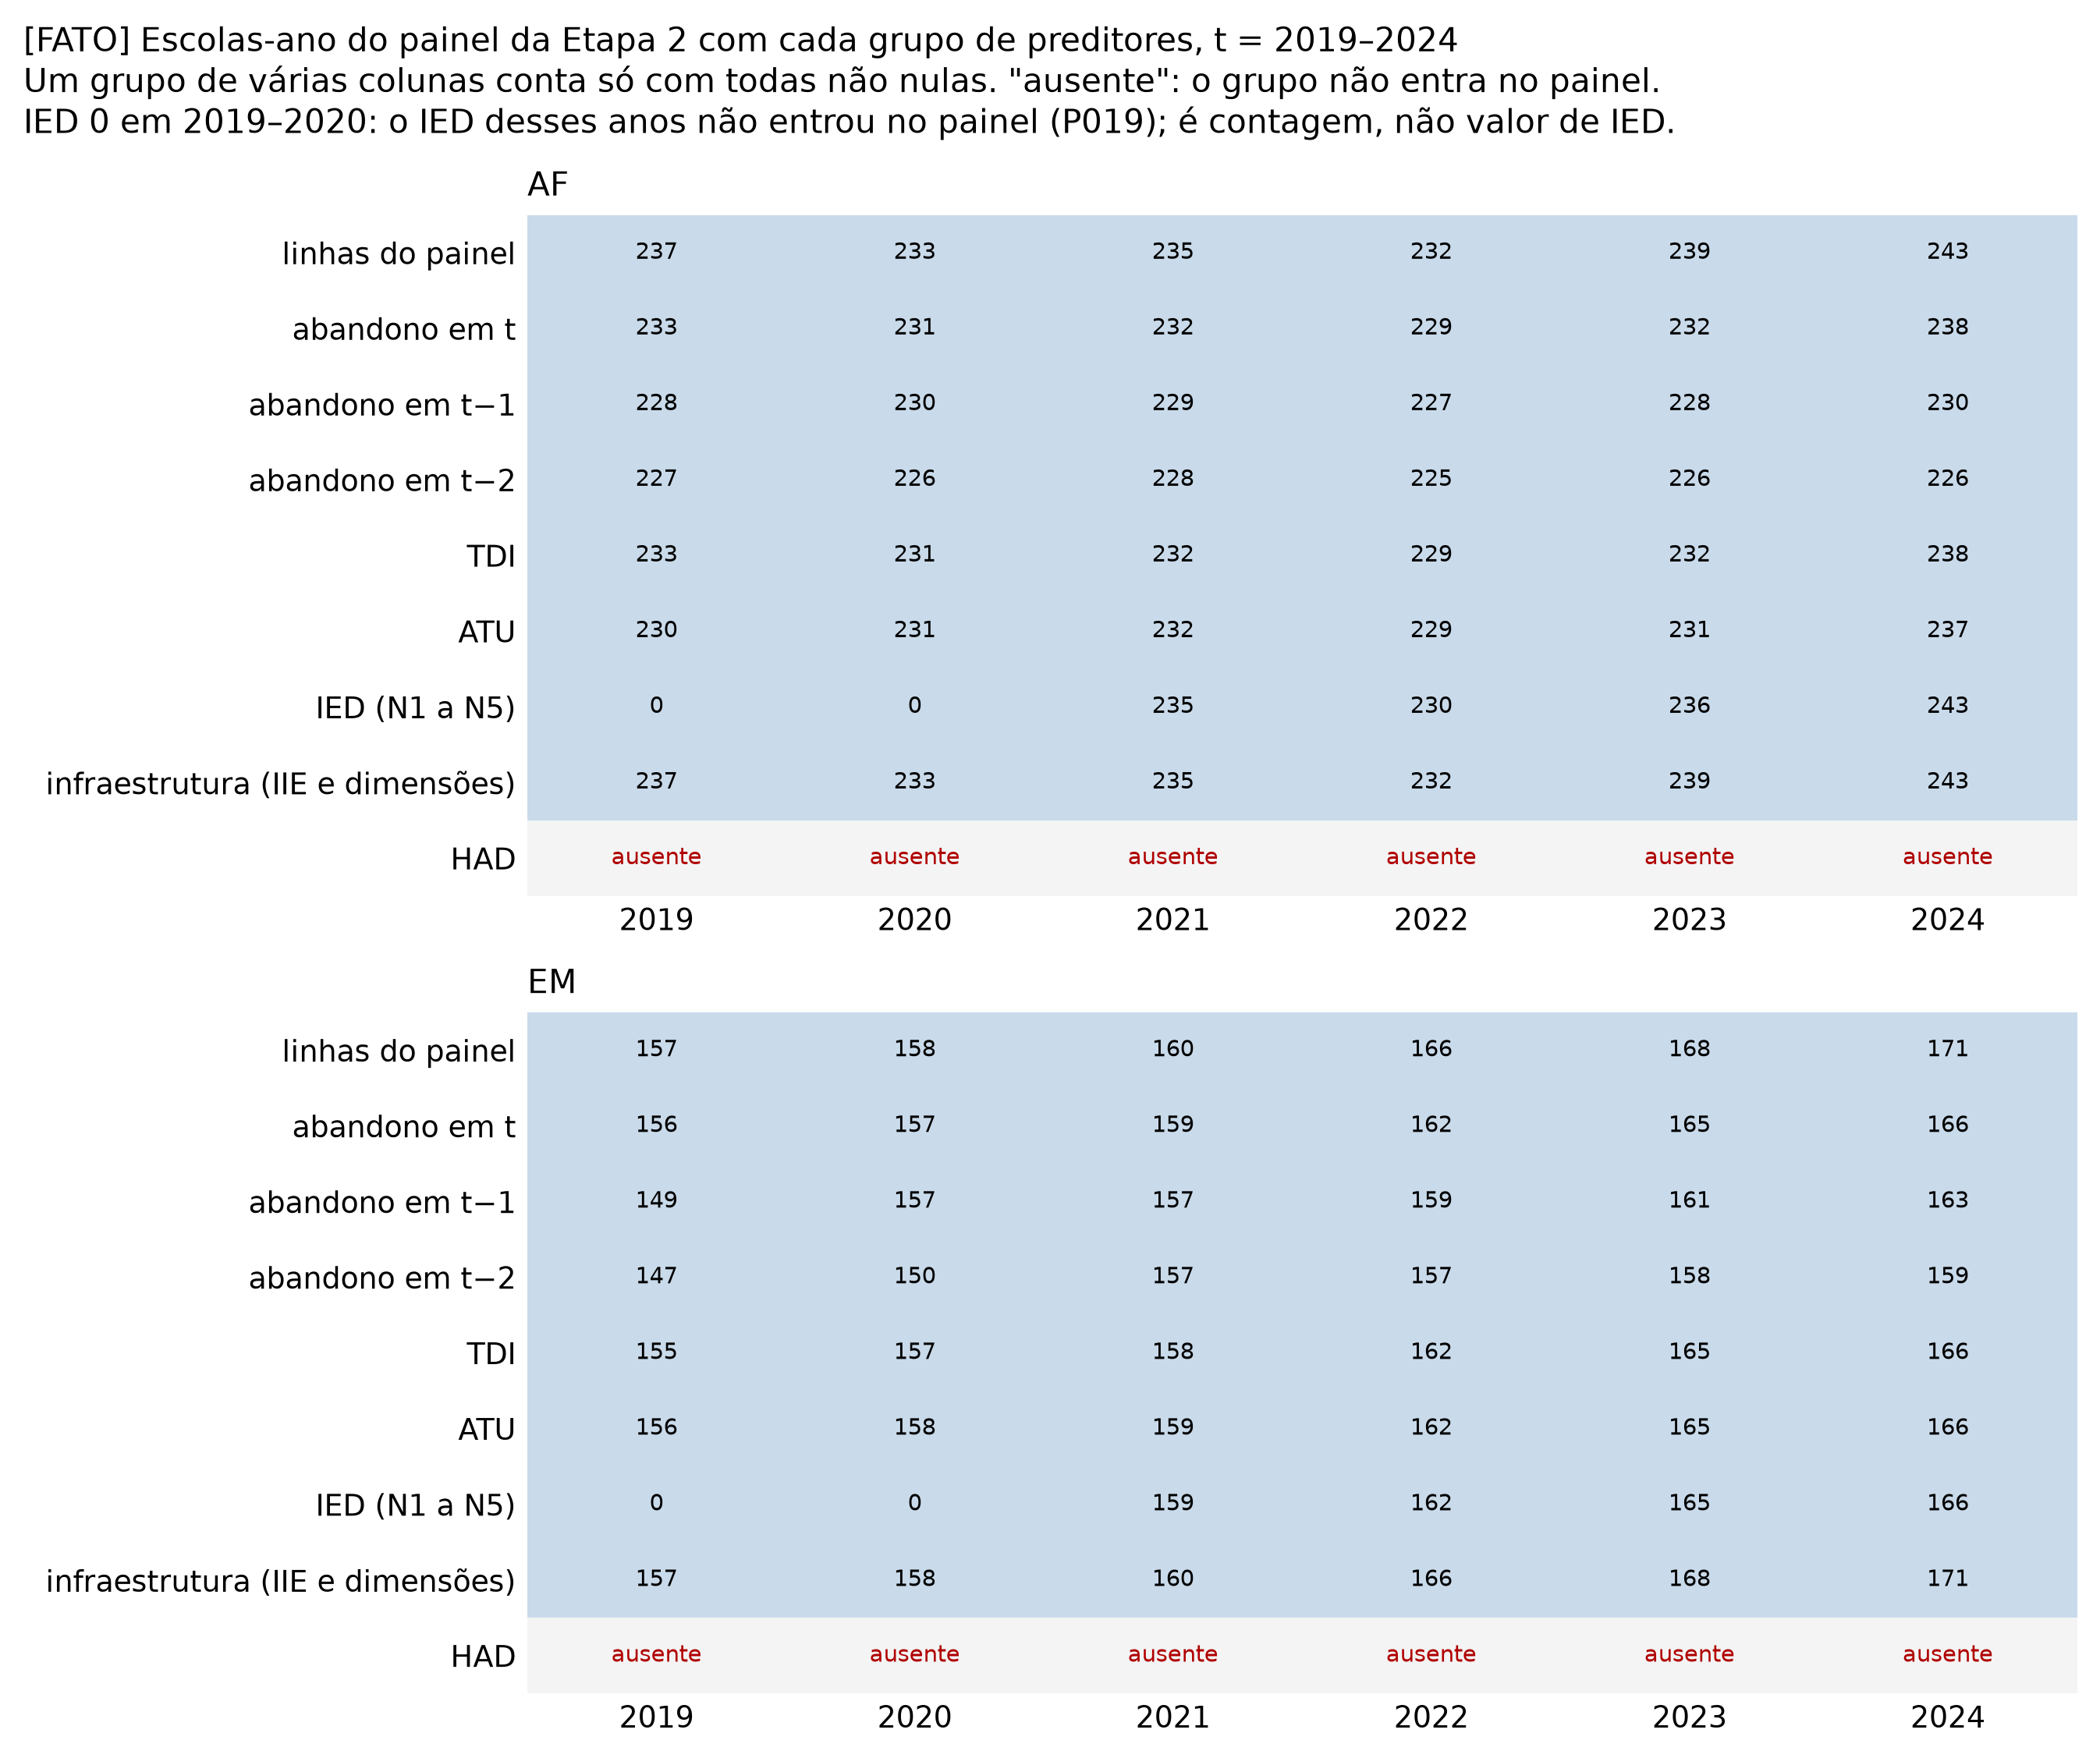

In [14]:
figura_existente(GUSTAVO / "saida" / "figuras" / "02_cobertura_painel.png", largura=800)

# Parte E — Problemas conhecidos e enriquecimento

## 9. O que aconteceu com o enriquecimento planejado em outubro

| Item (prioridade de outubro) | Estado em 10/11/2026 | Registro |
|---|---|---|
| 1. Escola indígena e localização diferenciada | **proposta D8**, não trazida; sem ela não há avaliação de equidade por estrato | metodologia §4.7; P018 |
| 2. Indicador de elegibilidade (escola só de infantil) | proposta **P017** (tirar do universo; 176 escolas em 2019) | `problemas.csv` |
| 3. Multisseriada | proposta **D9** (`ATU_FUN_TOTAL` + `IN_MULTISSERIADA`) | P016 |
| 4. Pé-de-Meia | não construído | síntese §5.5 |
| 5. IED 2019–2020 e HAD | **baixados** (estão em `dados/origem/`), nunca usados | P019 (linha proposta) |
| 6. INSE | nunca carregado; só serviria para comparar grupos | síntese §5.5 |
| 7. Infraestrutura do Censo | **feita** pelo Gustavo (18 itens, 4 dimensões, IIE) e **testada**: 0 de 8 testes de importância; sai do modelo e fica como estratificação | `DECISOES.md` 2026-11-02 |

**Fase 3 suspensa** desde 02/11/2026: nenhuma variável nova entra enquanto o instrumento não separar nada.
O princípio de outubro, "pôr tudo na base e decidir pelos experimentos", foi substituído por blocos
declarados antes de rodar e pela proibição de escolher variável pela correlação com o desfecho (regra 3).

## 10. O registro de problemas

O `docs/problemas.csv` é mantido à mão pela pesquisadora; o código não escreve nele. Há linhas propostas
(P006 corrigida, P019–P023, P027) aguardando a pesquisadora colar. A figura mostra o estado atual do arquivo.

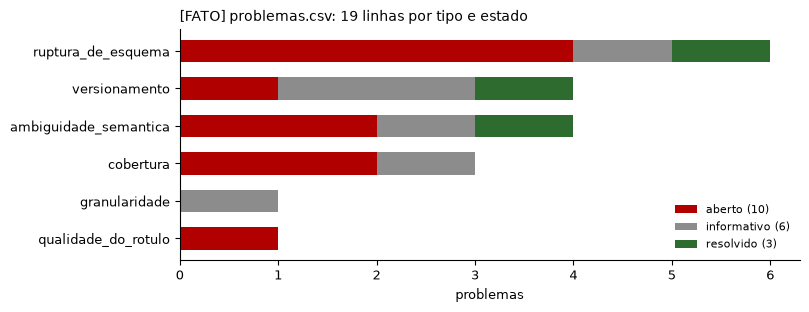

In [15]:
pr = t["problemas"].pivot(index="tipo", columns="status", values="problemas").fillna(0).astype(int)
pr = pr.loc[pr.sum(axis=1).sort_values().index]
cores = {"aberto": D.VERMELHO, "informativo": D.CINZA, "resolvido": "#2e6b2e"}
fig, ax = plt.subplots(figsize=(8, 3))
esquerda = pd.Series(0, index=pr.index)
for c in [c for c in ["aberto", "informativo", "resolvido"] if c in pr.columns]:
    ax.barh(pr.index, pr[c], left=esquerda, color=cores[c], label=f"{c} ({pr[c].sum()})", height=0.6)
    esquerda = esquerda + pr[c]
ax.set_xlabel("problemas")
ax.legend(loc="lower right", fontsize=8)
F.titulo(ax, f"problemas.csv: {pr.values.sum()} linhas por tipo e estado", "FATO")
F.salvar(fig, FIGURAS, "02_problemas")
plt.show()

## 11. Resumo dos limites dos dados

| # | Limite | Consequência |
|---|---|---|
| 1 | Ausência estrutural (etapa, multisseriada, fonte inexistente) | um painel por etapa; ausência nunca vira 0; `DISP_*` como controle |
| 2 | Massa em zero, sobretudo em 2020 | métrica de ordem (Recall@K); R² e MAE não decidem |
| 3 | Ruptura de 2020–2021 | ficam na base, com sensibilidade S1–S4 (não rodada) |
| 4 | IED só desde 2021 | só 2 anos de teste com IED no treino; resultado nulo e subtestado |
| 5 | Persistência fraca e poucas escolas por ano | intervalo largo (~0,30) no Recall@10% de um ano |
| 6 | Defasagem do desfecho | o abandono de *t* não existe na hora de decidir: Cenário B e B1R_lag |
| 7 | 2007–2018 não reverificável nesta máquina | a extensão D11 depende de rebaixar e registrar esses zips |
| 8 | Revisões silenciosas do INEP | versão fixada por sha256; a versão anterior dos zips 2024/2025 não existe no projeto |